## CS 329E - Data Science
#### Fall 2026 - Group 8
Name: Eduardo Borges Issa

EID: eb34276

Name: Cheve Garcia

EID

Dataset: UCI Adult Dataset (Census Income dataset), extracted from the 1994 US Census Bureau database. It contains demographic, financial, and employment records for approximately 48,842 instances. (https://archive.ics.uci.edu/dataset/2/adult)

#### Problem Statement & Research Question
The research question will investigate what demographic and employment features best predict annual incomes exceeding $50,000, and how effectively class imbalance resampling can mitigate minority class misclassification. To satisfy the requirement for an uncovered technique, the project will be done with SMOTE (Synthetic Minority Over-sampling Technique), which will generate synthetic minority instances by interpolating feature-space nearest neighbors via Euclidean distance to avoid the overfitting risks of naive random duplication. 


In [1]:
# Cell 1: Import core data science, modeling, and evaluation libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Set visual plotting styles
sns.set_theme(style="whitegrid")
%matplotlib inline

In [2]:
# Cell 2: Load the training dataset from the 'adult' subfolder
columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education_num",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
    "native_country",
    "income",
]

# We load only adult.data (32,561 raw rows) and create our own stratified split later
df = pd.read_csv(
    "adult/adult.data", header=None, names=columns, skipinitialspace=True
)

print(f"Raw dataset shape: {df.shape}")
df.head()

Raw dataset shape: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
# Cell 3: Data Cleaning & Missing Value Handling
# Replace whitespace-padded question marks with NaN
df = df.replace(r"^\s*\?\s*$", np.nan, regex=True)

# Fixed for Pandas 2.x/3.x compatibility using exclude="number"
str_cols = df.select_dtypes(exclude="number").columns
df[str_cols] = df[str_cols].apply(lambda x: x.str.strip())

# Inspect missing values count
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Drop rows with missing values (dropped 2,399 rows, exactly 7.4% of the dataset)
df_clean = df.dropna().copy()
print(f"\nOriginal shape: {df.shape}")
print(f"Shape after dropping missing rows: {df_clean.shape}")

Missing values per column:
workclass         1836
occupation        1843
native_country     583
dtype: int64

Original shape: (32561, 15)
Shape after dropping missing rows: (30162, 15)


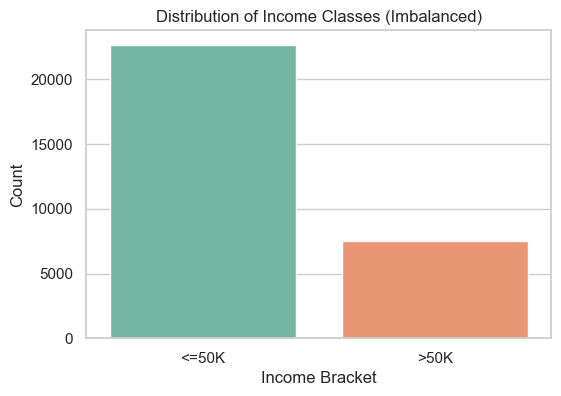

In [4]:
# Cell 4: Target Distribution Visualization
plt.figure(figsize=(6, 4))
sns.countplot(
    x="income", hue="income", data=df_clean, palette="Set2", legend=False
)
plt.title("Distribution of Income Classes (Imbalanced)")
plt.xlabel("Income Bracket")
plt.ylabel("Count")
plt.show()

In [5]:
# Cell 5: Preprocessing and SMOTE Resampling
# Drop target, survey weight (fnlwgt), and redundant 'education' (fully captured by education_num)
X = df_clean.drop(columns=["income", "fnlwgt", "education"])
y = df_clean["income"].apply(lambda x: 1 if x == ">50K" else 0)

numerical_cols = X.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns
categorical_cols = X.select_dtypes(exclude="number").columns

# 80/20 Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Preprocessor with verbose_feature_names_out=False to keep feature names clean in plots
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_cols,
        ),
    ],
    verbose_feature_names_out=False,
)

# Transform datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Training feature matrix shape: {X_train_processed.shape}")

# Apply SMOTE exclusively to the training set to prevent data leakage
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_processed, y_train
)

print(
    f"Before SMOTE - Training class distribution: {np.bincount(y_train)}"
)
print(
    f"After SMOTE  - Training class distribution: {np.bincount(y_train_resampled)}"
)

Training feature matrix shape: (24129, 87)
Before SMOTE - Training class distribution: [18123  6006]
After SMOTE  - Training class distribution: [18123 18123]


In [6]:
# Cell 6: Train Baseline Model (No SMOTE) and SMOTE Model
# 1. Baseline Logistic Regression (Imbalanced data)
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train_processed, y_train)

# 2. SMOTE Logistic Regression (Balanced training data)
smote_model = LogisticRegression(max_iter=1000, random_state=42)
smote_model.fit(X_train_resampled, y_train_resampled)

print("Both Logistic Regression models trained successfully!")

Both Logistic Regression models trained successfully!


=== BASELINE MODEL (No SMOTE) ===
              precision    recall  f1-score   support

           0       0.88      0.93      0.90      4531
           1       0.73      0.60      0.66      1502

    accuracy                           0.85      6033
   macro avg       0.80      0.76      0.78      6033
weighted avg       0.84      0.85      0.84      6033


=== SMOTE MODEL (Balanced Training) ===
              precision    recall  f1-score   support

           0       0.93      0.80      0.86      4531
           1       0.58      0.82      0.68      1502

    accuracy                           0.81      6033
   macro avg       0.75      0.81      0.77      6033
weighted avg       0.84      0.81      0.81      6033



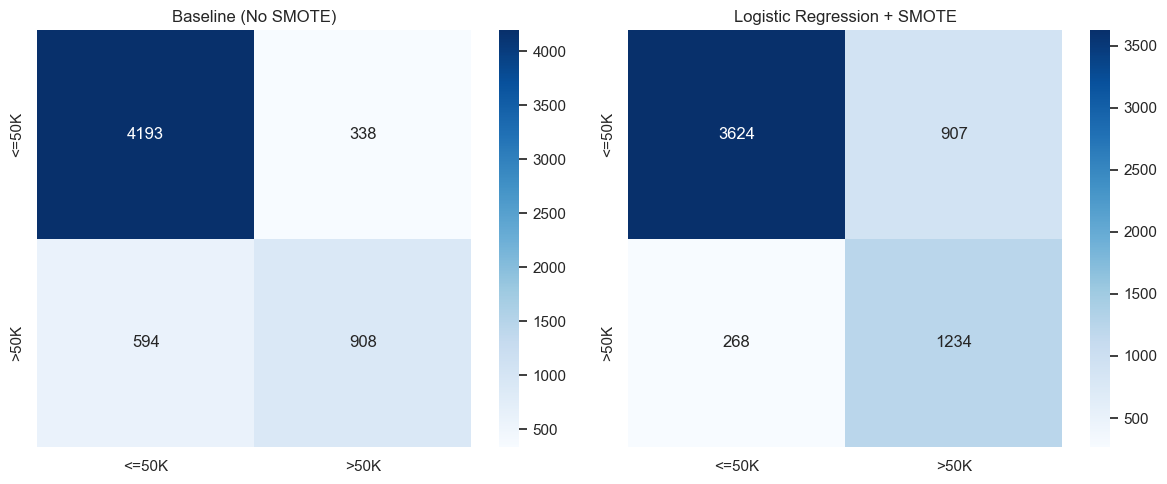

ROC-AUC (SMOTE model): 0.9007


In [11]:
# Cell 7: Side-by-Side Evaluation and Confusion Matrices
y_pred_base = baseline_model.predict(X_test_processed)
y_pred_smote = smote_model.predict(X_test_processed)
y_prob_smote = smote_model.predict_proba(X_test_processed)[:, 1]

print("=== BASELINE MODEL (No SMOTE) ===")
print(classification_report(y_test, y_pred_base))

print("\n=== SMOTE MODEL (Balanced Training) ===")
print(classification_report(y_test, y_pred_smote))

# Side-by-side Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, y_pred_base),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"],
)
axes[0].setTitle = "Baseline Confusion Matrix"
axes[0].set_title("Baseline (No SMOTE)")

sns.heatmap(
    confusion_matrix(y_test, y_pred_smote),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1],
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"],
)
axes[1].set_title("Logistic Regression + SMOTE")

plt.tight_layout()
plt.show()

print(f"ROC-AUC (SMOTE model): {roc_auc_score(y_test, y_prob_smote):.4f}")

In [8]:
# Cell 8: Improvement Step - Validation-Based Threshold Tuning
# Split a validation set from the ORIGINAL (pre-SMOTE) training data
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_processed, y_train, test_size=0.2, random_state=42, stratify=y_train
)

# Apply SMOTE only to the sub-training portion
X_tr_res, y_tr_res = SMOTE(random_state=42).fit_resample(X_tr, y_tr)
tuning_model = LogisticRegression(max_iter=1000, random_state=42)
tuning_model.fit(X_tr_res, y_tr_res)

# Tune the threshold on real (non-synthetic) validation data
val_probs = tuning_model.predict_proba(X_val)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_val, val_probs)
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-10)
best_threshold = thresholds[np.argmax(f1_scores[:-1])]
print(f"Optimal threshold (tuned on validation data): {best_threshold:.4f}")

# Apply the SAME model and threshold to the test set
test_probs = tuning_model.predict_proba(X_test_processed)[:, 1]
y_pred_tuned = (test_probs >= best_threshold).astype(int)
print("\n=== SMOTE MODEL WITH TUNED THRESHOLD (Test Set) ===")
print(classification_report(y_test, y_pred_tuned))

Optimal threshold (tuned on validation data): 0.5974

=== SMOTE MODEL WITH TUNED THRESHOLD (Test Set) ===
              precision    recall  f1-score   support

           0       0.91      0.85      0.88      4531
           1       0.63      0.76      0.69      1502

    accuracy                           0.83      6033
   macro avg       0.77      0.80      0.78      6033
weighted avg       0.84      0.83      0.83      6033



In [9]:
# Cell 8b: Improvement Step - Random Forest with SMOTE
rf_model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_model.fit(X_train_resampled, y_train_resampled)
print("=== RANDOM FOREST + SMOTE ===")
print(classification_report(y_test, rf_model.predict(X_test_processed)))

=== RANDOM FOREST + SMOTE ===
              precision    recall  f1-score   support

           0       0.89      0.89      0.89      4531
           1       0.67      0.68      0.67      1502

    accuracy                           0.84      6033
   macro avg       0.78      0.78      0.78      6033
weighted avg       0.84      0.84      0.84      6033



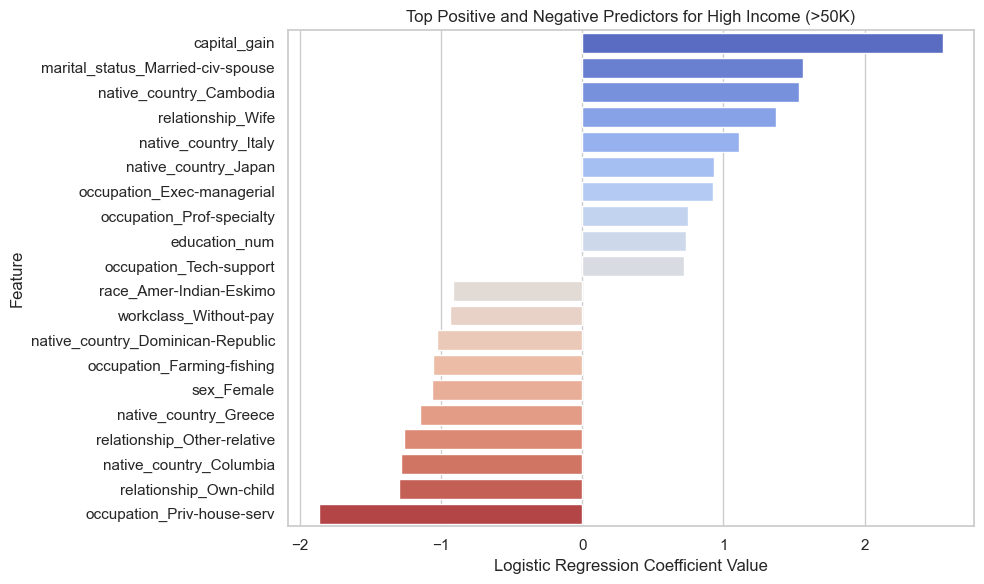

In [10]:
# Cell 9: Logistic Regression Coefficient Analysis
feature_names = preprocessor.get_feature_names_out()
coef_df = pd.DataFrame(
    {"Feature": feature_names, "Coefficient": smote_model.coef_[0]}
)
coef_df = coef_df.sort_values(by="Coefficient", ascending=False)

plt.figure(figsize=(10, 6))
top_features = pd.concat([coef_df.head(10), coef_df.tail(10)])
sns.barplot(
    x="Coefficient",
    y="Feature",
    data=top_features,
    hue="Feature",
    palette="coolwarm",
    legend=False,
)
plt.title("Top Positive and Negative Predictors for High Income (>50K)")
plt.xlabel("Logistic Regression Coefficient Value")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()